# Mask R-CNN - Train oilwell Model

In [1]:
import os
import random
import numpy as np

SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)


random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf

tf.random.set_seed(SEED)


In [2]:
import sys
import datetime
import skimage.draw
from skimage.measure import label
import matplotlib.pyplot as plt
from tqdm import tqdm
# Root directory of the project
ROOT_DIR = os.path.abspath("../../")
sys.path.append(ROOT_DIR)


import mrcnn.model as modellib
from mrcnn import utils
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import TensorBoard
from mrcnn import visualize, utils

%matplotlib inline 

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT_DIR, "tesRP/logs")



In [3]:
from mrcnn.config import Config

In [4]:
DATASET_DIR = os.path.join(ROOT_DIR, "datasets/New/augmented_images")
#LOGS_DIR = os.path.join(ROOT_DIR, "logs")
COCO_WEIGHTS_PATH = os.path.join(ROOT_DIR, "mask_rcnn_coco.h5")

In [5]:
class OilwellConfig(Config):
    NAME = "oilwell"
    NUM_CLASSES = 1 + 1  # background + oilwell
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1
    IMAGE_MIN_DIM = 512
    IMAGE_MAX_DIM = 512
    IMAGE_RESIZE_MODE = "none"
    STEPS_PER_EPOCH = 100
    DETECTION_MIN_CONFIDENCE = 0.9

In [6]:
# class OilWellDataset(utils.Dataset):
#     def load_oilwells(self, dataset_dir, subset):
#         """Load a subset of the OilWell dataset."""
#         # Add class
#         self.add_class("oilwell", 1, "oilwell")
        
#         # Path to images and masks
#         assert subset in ["train", "val", "test"]
#         subset_dir = os.path.join(dataset_dir, subset)
#         image_dir = os.path.join(subset_dir, "images")
#         mask_dir = os.path.join(subset_dir, "masks")
        
#         # List image files
#         for filename in os.listdir(image_dir):
#             if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
#                 continue
#             image_path = os.path.join(image_dir, filename)
#             mask_path = os.path.join(mask_dir, filename)  # assumes mask has same name

#             # Read image to get size
#             image = skimage.io.imread(image_path)
#             height, width = image.shape[:2]

#             self.add_image(
#                 "oilwell",
#                 image_id=filename,
#                 path=image_path,
#                 width=width, height=height,
#                 mask_path=mask_path
#             )

#     def load_mask(self, image_id):
#         """Generate instance masks for an image."""
#         image_info = self.image_info[image_id]
#         if image_info["source"] != "oilwell":
#             return super(self.__class__, self).load_mask(image_id)
        
#         # Read the saved raster mask (0 background, >0 well pixels)
#         info = self.image_info[image_id]
#         m = skimage.io.imread(info["mask_path"])
#         if m.ndim == 3:
#             m = m[..., 0]

#         # Convert to binary
#         m = (m > 0)

#         # Split into instances using connected components
#         labeled = label(m, connectivity=2)  # 8-connected
#         instance_ids = np.unique(labeled)
#         instance_ids = instance_ids[instance_ids != 0]  # remove background

#         # If no wells in this tile
#         if instance_ids.size == 0:
#             mask = np.zeros([info["height"], info["width"], 0], dtype=bool)
#             class_ids = np.array([], dtype=np.int32)
#             return mask, class_ids

#         # Build instance mask stack: [H, W, instance_count]
#         mask = np.zeros([info["height"], info["width"], instance_ids.size], dtype=np.uint8)
#         for i, inst_id in enumerate(instance_ids):
#             mask[:, :, i] = (labeled == inst_id).astype(np.uint8)

#         # Return boolean masks + class IDs (all 1 because one class)
#         return mask.astype(bool), np.ones([mask.shape[-1]], dtype=np.int32)


# def image_reference(self, image_id):
#     """Return the path of the image."""
#     info = self.image_info[image_id]

#     if info["source"] == "oilwell":
#         return info["path"]
#     else:
#         return super(self.__class__, self).image_reference(image_id)

In [ ]:
class OilWellDataset(utils.Dataset):
    def load_oilwells(self, dataset_dir, subset):
        """Load a subset of the OilWell dataset."""
        # Add class
        self.add_class("oilwell", 1, "oilwell")
        
        # Path to images and masks
        assert subset in ["train", "val", "test"]
        subset_dir = os.path.join(dataset_dir, subset)
        image_dir = os.path.join(subset_dir, "images")
        mask_dir = os.path.join(subset_dir, "masks")
        
        # List image files
        for filename in os.listdir(image_dir):
            if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
                continue
            image_path = os.path.join(image_dir, filename)
            mask_path = os.path.join(mask_dir, filename)  # assumes mask has same name

            # Read image to get size
            image = skimage.io.imread(image_path)
            height, width = image.shape[:2]

            self.add_image(
                "oilwell",
                image_id=filename,
                path=image_path,
                width=width, height=height,
                mask_path=mask_path
            )

    def load_mask(self, image_id):
        """Generate instance masks for an image."""
        MIN_WELL_AREA = 0  # minimum area in pixels to consider a valid well instance
        image_info = self.image_info[image_id]
        if image_info["source"] != "oilwell":
            return super(self.__class__, self).load_mask(image_id)
        
        # Read the saved raster mask (0 background, >0 well pixels)
        info = self.image_info[image_id]
        m = skimage.io.imread(info["mask_path"])
        if m.ndim == 3:
            m = m[..., 0]

        # Convert to binary
        m = (m > 0)

        # Split into instances using connected components
        labeled = label(m, connectivity=2)  # 8-connected
        instance_ids = np.unique(labeled)
        instance_ids = instance_ids[instance_ids != 0]  # remove background

        valid_instance_ids = []
        for inst_id in instance_ids:
            area = np.sum(labeled == inst_id)
            if area >= MIN_WELL_AREA:
                valid_instance_ids.append(inst_id)

        instance_ids = np.array(valid_instance_ids)

        # If no wells in this tile
        if instance_ids.size == 0:
            mask = np.zeros([info["height"], info["width"], 0], dtype=bool)
            class_ids = np.array([], dtype=np.int32)
            return mask, class_ids

        # Build instance mask stack: [H, W, instance_count]
        mask = np.zeros([info["height"], info["width"], instance_ids.size], dtype=np.uint8)
        for i, inst_id in enumerate(instance_ids):
            mask[:, :, i] = (labeled == inst_id).astype(np.uint8)

        # Return boolean masks + class IDs (all 1 because one class)
        return mask.astype(bool), np.ones([mask.shape[-1]], dtype=np.int32)


def image_reference(self, image_id):
    """Return the path of the image."""
    info = self.image_info[image_id]

    if info["source"] == "oilwell":
        return info["path"]
    else:
        return super(self.__class__, self).image_reference(image_id)

In [8]:
config = OilwellConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     1
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        35
DETECTION_MIN_CONFIDENCE       0.9
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 1
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  512
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  512
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              none
IMAGE_SHAPE                    [512 512   3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE                

In [9]:
model = modellib.MaskRCNN(mode="training", config=config, model_dir=MODEL_DIR)

In [10]:
model.load_weights(COCO_WEIGHTS_PATH, by_name=True, exclude=[
            "mrcnn_class_logits", "mrcnn_bbox_fc",
            "mrcnn_bbox", "mrcnn_mask"])

In [11]:
# Training dataset.
dataset_train = OilWellDataset()
dataset_train.load_oilwells(DATASET_DIR, "train")
dataset_train.prepare()

# Validation dataset
dataset_val = OilWellDataset()
dataset_val.load_oilwells(DATASET_DIR, "val")
dataset_val.prepare()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,              # stop if no improvement for 8 epochs
    restore_best_weights=True
)

log_dir = os.path.join("logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

tensorboard = TensorBoard(
    log_dir=log_dir,
    histogram_freq=0,
    write_graph=True,
    update_freq='epoch'
)

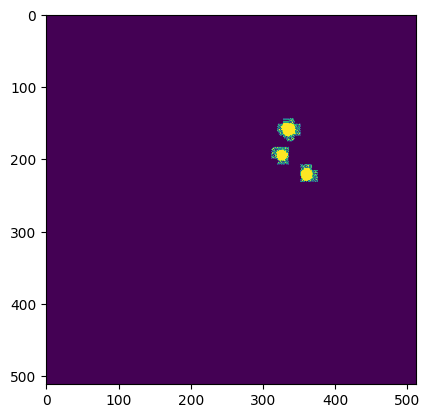

In [12]:
image_id = dataset_train.image_ids[346]

info = dataset_train.image_info[image_id]

well = skimage.io.imread(info["mask_path"])

plt.imshow(well)
plt.show()

In [13]:
mask, class_ids = dataset_train.load_mask(image_id)

print(mask.shape)
print(class_ids)

(512, 512, 3)
[1 1 1]


In [14]:
info = dataset_train.image_info[image_id]

m = skimage.io.imread(info["mask_path"])

if m.ndim == 3:
    m = m[..., 0]

print("Mask file:", info["mask_path"])
print("Unique values:", np.unique(m))
print("Min:", m.min())
print("Max:", m.max())

Mask file: c:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets/New/augmented_images\train\masks\img_1309.png
Unique values: [  0 255]
Min: 0
Max: 255


In [15]:
#Training network heads
model.train(dataset_train, dataset_val,
            learning_rate=config.LEARNING_RATE/10,
            epochs=200,
            layers='4+',
            custom_callbacks=[early_stopping, tensorboard])


Starting at epoch 0. LR=0.0001

Checkpoint Path: c:\oil_well_n\Code\Mask-RCNN_TF2.14.0\tesRP/logs\oilwell20260622T0903\mask_rcnn_oilwell_{epoch:04d}.h5
Selecting layers to train
res4a_branch2a         (Conv2D)
bn4a_branch2a          (BatchNorm)
res4a_branch2b         (Conv2D)
bn4a_branch2b          (BatchNorm)
res4a_branch2c         (Conv2D)
res4a_branch1          (Conv2D)
bn4a_branch2c          (BatchNorm)
bn4a_branch1           (BatchNorm)
res4b_branch2a         (Conv2D)
bn4b_branch2a          (BatchNorm)
res4b_branch2b         (Conv2D)
bn4b_branch2b          (BatchNorm)
res4b_branch2c         (Conv2D)
bn4b_branch2c          (BatchNorm)
res4c_branch2a         (Conv2D)
bn4c_branch2a          (BatchNorm)
res4c_branch2b         (Conv2D)
bn4c_branch2b          (BatchNorm)
res4c_branch2c         (Conv2D)
bn4c_branch2c          (BatchNorm)
res4d_branch2a         (Conv2D)
bn4d_branch2a          (BatchNorm)
res4d_branch2b         (Conv2D)
bn4d_branch2b          (BatchNorm)
res4d_branch2c   

c:\Users\iaadeniran\AppData\Local\ESRI\conda\envs\maskrcnn_env\lib\site-packages\keras\src\optimizers\legacy\gradient_descent.py:114: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


Epoch 1/200
100/100 [==============================] - ETA: 0s - batch: 49.5000 - size: 1.0000 - loss: 1.8196 - rpn_class_loss: 0.0772 - rpn_bbox_loss: 0.6367 - mrcnn_class_loss: 0.0324 - mrcnn_bbox_loss: 0.5714 - mrcnn_mask_loss: 0.5019

c:\Users\iaadeniran\AppData\Local\ESRI\conda\envs\maskrcnn_env\lib\site-packages\keras\src\engine\training_v1.py:2335: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates = self.state_updates


100/100 [==============================] - 567s 6s/step - batch: 49.5000 - size: 1.0000 - loss: 1.8196 - rpn_class_loss: 0.0772 - rpn_bbox_loss: 0.6367 - mrcnn_class_loss: 0.0324 - mrcnn_bbox_loss: 0.5714 - mrcnn_mask_loss: 0.5019 - val_loss: 1.4134 - val_rpn_class_loss: 0.0259 - val_rpn_bbox_loss: 0.4113 - val_mrcnn_class_loss: 0.0502 - val_mrcnn_bbox_loss: 0.4219 - val_mrcnn_mask_loss: 0.5041
Epoch 2/200
100/100 [==============================] - 539s 5s/step - batch: 49.5000 - size: 1.0000 - loss: 1.5896 - rpn_class_loss: 0.0391 - rpn_bbox_loss: 0.5555 - mrcnn_class_loss: 0.0454 - mrcnn_bbox_loss: 0.4545 - mrcnn_mask_loss: 0.4951 - val_loss: 1.4031 - val_rpn_class_loss: 0.0209 - val_rpn_bbox_loss: 0.4255 - val_mrcnn_class_loss: 0.0236 - val_mrcnn_bbox_loss: 0.4104 - val_mrcnn_mask_loss: 0.5227
Epoch 3/200
100/100 [==============================] - 539s 5s/step - batch: 49.5000 - size: 1.0000 - loss: 1.4859 - rpn_class_loss: 0.0271 - rpn_bbox_loss: 0.5528 - mrcnn_class_loss: 0.0362 -

In [16]:
class InferenceConfig(OilwellConfig):  
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1  # inference on one image at a time

In [17]:
inference_config = InferenceConfig()

model_infer = modellib.MaskRCNN(
    mode="inference",
    config=inference_config,
    model_dir=log_dir
)

# Load the best weights from training
best_model_path = model.find_last()  # or your saved weights file
# best_model_path = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\tesRP\logs\oilwell20260530T1812\mask_rcnn_oilwell_0036.h5"
model_infer.load_weights(best_model_path, by_name=True)

Instructions for updating:
Use fn_output_signature instead
Re-starting from epoch 58


In [18]:
def _ensure_rgb3(image):
    """Ensure image is HxWx3 for Mask R-CNN."""
    if image.ndim == 2:
        image = np.stack([image]*3, axis=-1)
    elif image.ndim == 3 and image.shape[2] == 1:
        image = np.repeat(image, 3, axis=2)
    return image

def _union_mask(mask_3d, H, W):
    """[H,W,N] -> [H,W] boolean union mask"""
    if mask_3d is None or mask_3d.size == 0:
        return np.zeros((H, W), dtype=bool)
    if mask_3d.ndim == 2:
        return mask_3d.astype(bool)
    return (np.sum(mask_3d, axis=-1) > 0)

In [19]:
def save_overlays_and_metrics(model, dataset, out_dir, score_thresh=0.8, limit=None):
    os.makedirs(out_dir, exist_ok=True)

    # separate folders by TP/FP/FN/TN
    for sub in ["TP", "FP", "FN", "TN"]:
        os.makedirs(os.path.join(out_dir, sub), exist_ok=True)

    ids = dataset.image_ids[:limit] if limit else dataset.image_ids

    TP = FP = FN = TN = 0

    # store per-image results
    results_rows = []

    for image_id in tqdm(ids):
        image = dataset.load_image(image_id)
        image = _ensure_rgb3(image)
        H, W = image.shape[:2]

        # GET REAL FILENAME
        image_info = dataset.image_info[image_id]
        filename = os.path.splitext(os.path.basename(image_info["path"]))[0]

        gt_mask, _ = dataset.load_mask(image_id)
        gt_any = bool(gt_mask.size > 0 and np.sum(gt_mask) > 0)
        gt_u = _union_mask(gt_mask, H, W)

        r = model.detect([image], verbose=0)[0]

        # filter by threshold
        if r["scores"].size:
            keep = r["scores"] >= score_thresh
            pred_masks = (
                r["masks"][:, :, keep]
                if np.any(keep)
                else np.zeros((H, W, 0), dtype=bool)
            )
        else:
            pred_masks = np.zeros((H, W, 0), dtype=bool)

        pred_any = pred_masks.shape[-1] > 0
        pr_u = _union_mask(pred_masks, H, W)

        # confusion
        if gt_any and pred_any:
            TP += 1
            status = "TP"
        elif (not gt_any) and pred_any:
            FP += 1
            status = "FP"
        elif gt_any and (not pred_any):
            FN += 1
            status = "FN"
        else:
            TN += 1
            status = "TN"

        # ---------------------------
        # STORE RESULTS
        # ---------------------------
        max_score = (
            float(np.max(r["scores"])) if r["scores"].size > 0 else 0.0
        )

        results_rows.append({
            "filename": filename,
            "status": status,
            "gt_present": gt_any,
            "prediction_present": pred_any,
            "num_predictions": int(pred_masks.shape[-1]),
            "max_score": round(max_score, 4)
        })

        # save overlay image
        fig = plt.figure(figsize=(12, 4))

        ax1 = fig.add_subplot(1, 3, 1)
        ax1.imshow(image)
        ax1.set_title("Image")
        ax1.axis("off")

        ax2 = fig.add_subplot(1, 3, 2)
        ax2.imshow(image)
        ax2.imshow(np.ma.masked_where(~gt_u, gt_u), alpha=0.5)
        ax2.set_title("GT")
        ax2.axis("off")

        ax3 = fig.add_subplot(1, 3, 3)
        ax3.imshow(image)
        ax3.set_title(f"Pred ({status})")
        ax3.axis("off")

        rois = r["rois"]
        masks = r["masks"]
        class_ids = r["class_ids"]
        scores = r["scores"]

        for i in range(rois.shape[0]):
            if scores[i] < score_thresh:
                continue

            y1, x1, y2, x2 = rois[i]

            # mask overlay
            mask = masks[:, :, i]
            ax3.imshow(np.ma.masked_where(~mask, mask), alpha=0.4)

            # label text
            label = dataset.class_names[class_ids[i]]
            score = scores[i]

            ax3.text(
                x1, y1,
                f"{label} {score:.2f}",
                color="white",
                fontsize=8,
                bbox=dict(facecolor="red", alpha=0.5, pad=2)
            )

        plt.tight_layout()

        out_path = os.path.join(out_dir, status, f"{filename}.png")
        plt.savefig(out_path, dpi=120)
        plt.close(fig)

    # =========================
    # METRICS
    # =========================
    total = TP + FP + FN + TN

    accuracy  = (TP + TN) / total if total else 0.0
    precision = TP / (TP + FP) if (TP + FP) else 0.0
    recall    = TP / (TP + FN) if (TP + FN) else 0.0
    f1        = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0.0
    )

    print("\nConfusion (image-level presence/absence):")
    print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}  (Total={total})")

    print("\nMetrics:")
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1       : {f1:.3f}")



    print(f"Saved overlays to: {out_dir}")

    # =========================
    # SAVE TO EXCEL
    # =========================

    obj_metrics = compute_metrics(model, dataset)

    metrics_df = pd.DataFrame({
    "Count Metrics": ["TP", "FP", "FN", "TN", "Total"],
    "Value": [TP, FP, FN, TN, total],
    "Performance Metrics": ["Accuracy", "Precision", "Recall", "F1", ""],
    "Value ": [round(accuracy, 4), round(precision, 4), round(recall, 4), round(f1, 4),""],
    "Object Metrics": ["mAP@50", "mAP@75", "mAP", "Mean IoU", ""],

    "Value  ": [ round(obj_metrics["mAP50"], 4), round(obj_metrics["mAP75"], 4), round(obj_metrics["mAP"], 4),
        round(obj_metrics["mean_IoU"], 4), "" ]

})

    
    results_df = pd.DataFrame(results_rows)

    excel_path = os.path.join(out_dir, "evaluation_results.xlsx")

    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        results_df.to_excel(writer, sheet_name="Per_Image_Results", index=False)
        metrics_df.to_excel(writer, sheet_name="Summary_Metrics", index=False)

    print(f"Excel report saved to: {excel_path}")

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [20]:
def compute_metrics(model_infer, dataset_test):
    image_ids = dataset_test.image_ids

    APs = []
    AP50s = []
    AP75s = []
    IoUs = []

    empty_images = 0
    false_positives = 0

    for image_id in image_ids:

        # Load image and GT
        image, image_meta, gt_class_id, gt_bbox, gt_mask = \
            modellib.load_image_gt(dataset_test, config, image_id)
        
        # Run inference
        results = model_infer.detect([image], verbose=0)
        r = results[0]

        num_gt = len(gt_class_id)
        num_pred = len(r["class_ids"])

        # Track empty images
        if num_gt == 0:
            empty_images += 1

        # CASE 1: No GT and No Prediction -> True Negative

        if num_gt == 0 and num_pred == 0:

            AP50s.append(1.0)
            AP75s.append(1.0)
            APs.append(1.0)
            IoUs.append(1.0)

        # CASE 2: No GT but Prediction exists -> False Positive

        elif num_gt == 0 and num_pred > 0:

            false_positives += 1

            AP50s.append(0.0)
            AP75s.append(0.0)
            APs.append(0.0)
            IoUs.append(0.0)

        # CASE 3: GT exists but no Prediction -> False Negative

        elif num_gt > 0 and num_pred == 0:

            AP50s.append(0.0)
            AP75s.append(0.0)
            APs.append(0.0)
            IoUs.append(0.0)
        
        # CASE 4: Normal detection evaluation

        else:

            # AP @ 0.50
            AP50, precisions, recalls, overlaps = utils.compute_ap(
                gt_bbox,
                gt_class_id,
                gt_mask,
                r["rois"],
                r["class_ids"],
                r["scores"],
                r["masks"],
                iou_threshold=0.5
            )

            # AP @ 0.75
            AP75, _, _, _ = utils.compute_ap(
                gt_bbox,
                gt_class_id,
                gt_mask,
                r["rois"],
                r["class_ids"],
                r["scores"],
                r["masks"],
                iou_threshold=0.75
            )

            # AP @ 1.00 (perfect overlap only)
            AP, _, _, _ = utils.compute_ap(
                gt_bbox,
                gt_class_id,
                gt_mask,
                r["rois"],
                r["class_ids"],
                r["scores"],
                r["masks"],
                iou_threshold=1.0
            )

            AP50s.append(AP50)
            AP75s.append(AP75)
            APs.append(AP)

            # Mean IoU
            if overlaps.size > 0:
                best_ious = overlaps.max(axis=1)
                IoUs.append(np.mean(best_ious))
            else:
                IoUs.append(0.0)

    # Final Metrics

    mAP50 = np.mean(AP50s)
    mAP75 = np.mean(AP75s)
    mAP = np.mean(APs)
    mean_IoU = np.mean(IoUs)

    # False Positive Rate on empty images
    fp_rate = false_positives / empty_images if empty_images > 0 else 0

    print(f"mAP@50   : {mAP50:.3f}")
    print(f"mAP@75   : {mAP75:.3f}")
    print(f"mAP  : {mAP:.3f}")
    print(f"Mean IoU : {mean_IoU:.3f}")
    print(f"FP Rate  : {fp_rate:.3f}")

    return {
        "mAP50": mAP50,
        "mAP75": mAP75,
        "mAP": mAP,
        "mean_IoU": mean_IoU
    }

In [21]:
import pandas as pd

In [22]:
out_dir=r"C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus"

In [23]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\Comb_siteA_n"
dataset_val = OilWellDataset()
dataset_val.load_oilwells(data_dir, "val")
dataset_val.prepare()

In [24]:
metrics_val = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_val,
    out_dir=os.path.join(out_dir, "Tpre_post1_val"),
    score_thresh=0.8
)

  0%|          | 0/400 [00:00<?, ?it/s]c:\Users\iaadeniran\AppData\Local\ESRI\conda\envs\maskrcnn_env\lib\site-packages\keras\src\engine\training_v1.py:2359: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,
100%|██████████| 400/400 [05:54<00:00,  1.13it/s]



Confusion (image-level presence/absence):
TP=319  FP=1  FN=0  TN=80  (Total=400)

Metrics:
Accuracy : 0.998
Precision: 0.997
Recall   : 1.000
F1       : 0.998
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\Tpre_post1_val
mAP@50   : 0.992
mAP@75   : 0.383
mAP  : 0.200
Mean IoU : 0.772
FP Rate  : 0.012
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\Tpre_post1_val\evaluation_results.xlsx


In [25]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\comb_siteA"
dataset_val = OilWellDataset()
dataset_val.load_oilwells(data_dir, "val")
dataset_val.prepare()

In [26]:
metrics_val = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_val,
    out_dir=os.path.join(out_dir, "pre_post1_val"),
    score_thresh=0.8
)

100%|██████████| 400/400 [05:43<00:00,  1.17it/s]



Confusion (image-level presence/absence):
TP=319  FP=0  FN=1  TN=80  (Total=400)

Metrics:
Accuracy : 0.998
Precision: 1.000
Recall   : 0.997
F1       : 0.998
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\pre_post1_val
mAP@50   : 0.991
mAP@75   : 0.208
mAP  : 0.200
Mean IoU : 0.723
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\pre_post1_val\evaluation_results.xlsx


In [27]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\Comb_siteA_n"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [28]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "TSiteA_prepost"),
    score_thresh=0.8
)

100%|██████████| 204/204 [03:14<00:00,  1.05it/s]



Confusion (image-level presence/absence):
TP=162  FP=0  FN=0  TN=42  (Total=204)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_prepost
mAP@50   : 1.000
mAP@75   : 0.415
mAP  : 0.206
Mean IoU : 0.779
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_prepost\evaluation_results.xlsx


In [29]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\comb_siteA"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [30]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "SiteA_prepost"),
    score_thresh=0.8
)

100%|██████████| 204/204 [03:01<00:00,  1.12it/s]



Confusion (image-level presence/absence):
TP=162  FP=0  FN=0  TN=42  (Total=204)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_prepost
mAP@50   : 0.993
mAP@75   : 0.210
mAP  : 0.206
Mean IoU : 0.729
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_prepost\evaluation_results.xlsx


In [31]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\SiteA_pre_n"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [32]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "TSiteA_pre"),
    score_thresh=0.8
)

100%|██████████| 102/102 [01:30<00:00,  1.13it/s]



Confusion (image-level presence/absence):
TP=81  FP=0  FN=0  TN=21  (Total=102)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_pre
mAP@50   : 1.000
mAP@75   : 0.396
mAP  : 0.206
Mean IoU : 0.778
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_pre\evaluation_results.xlsx


In [33]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\SiteA_pre"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [34]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "SiteA_pre"),
    score_thresh=0.8
)

100%|██████████| 102/102 [01:27<00:00,  1.16it/s]



Confusion (image-level presence/absence):
TP=81  FP=0  FN=0  TN=21  (Total=102)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_pre
mAP@50   : 0.990
mAP@75   : 0.207
mAP  : 0.206
Mean IoU : 0.727
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_pre\evaluation_results.xlsx


In [35]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\SiteA_post_n"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [36]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "TSiteA_post"),
    score_thresh=0.8
)

100%|██████████| 102/102 [01:30<00:00,  1.12it/s]



Confusion (image-level presence/absence):
TP=81  FP=0  FN=0  TN=21  (Total=102)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_post
mAP@50   : 1.000
mAP@75   : 0.434
mAP  : 0.206
Mean IoU : 0.780
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteA_post\evaluation_results.xlsx


In [37]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\SiteA_post"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [38]:
metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "SiteA_post"),
    score_thresh=0.8
)

100%|██████████| 102/102 [01:29<00:00,  1.14it/s]



Confusion (image-level presence/absence):
TP=81  FP=0  FN=0  TN=21  (Total=102)

Metrics:
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1       : 1.000
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_post
mAP@50   : 0.997
mAP@75   : 0.214
mAP  : 0.206
Mean IoU : 0.730
FP Rate  : 0.000
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteA_post\evaluation_results.xlsx


In [39]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\SiteB_post_n"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [40]:

metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "TSiteB"),
    score_thresh=0.80
)

100%|██████████| 102/102 [01:21<00:00,  1.26it/s]



Confusion (image-level presence/absence):
TP=80  FP=1  FN=0  TN=21  (Total=102)

Metrics:
Accuracy : 0.990
Precision: 0.988
Recall   : 1.000
F1       : 0.994
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteB
mAP@50   : 0.961
mAP@75   : 0.235
mAP  : 0.206
Mean IoU : 0.654
FP Rate  : 0.045
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\TSiteB\evaluation_results.xlsx


In [41]:
data_dir = r"C:\oil_well_n\Code\Mask-RCNN_TF2.14.0\datasets\New\siteB"
dataset_test = OilWellDataset()
dataset_test.load_oilwells(data_dir, "test")
dataset_test.prepare()

In [42]:

metrics_test = save_overlays_and_metrics(
    model=model_infer,
    dataset=dataset_test,
    out_dir=os.path.join(out_dir, "SiteB"),
    score_thresh=0.80
)

100%|██████████| 102/102 [01:20<00:00,  1.26it/s]



Confusion (image-level presence/absence):
TP=80  FP=1  FN=1  TN=20  (Total=102)

Metrics:
Accuracy : 0.980
Precision: 0.988
Recall   : 0.988
F1       : 0.988
Saved overlays to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteB
mAP@50   : 0.529
mAP@75   : 0.196
mAP  : 0.196
Mean IoU : 0.597
FP Rate  : 0.048
Excel report saved to: C:\new_overlays\nTES_aug2_rpn_anc8_cl_loss_rpn50_20_4plus\SiteB\evaluation_results.xlsx
